# Determining the Optimal Price:

In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
rng = np.random.default_rng(100)

def purchase_probability(price):
    price = np.asarray(price, dtype=float)
    return (
        0.55 * np.exp(-np.logaddexp(0.0, (price - 13.9) / 0.8))
        + 0.30 * np.exp(-np.logaddexp(0.0, (price - 30.9) / 1.2))
        + 0.15 * np.exp(-np.logaddexp(0.0, (price - 58.4) / 1.8))
    )

def sales(price=14.0, rng=None, mean_customers=30):
    price = float(price)
    if not np.isfinite(price):
        raise ValueError("price must be finite")
    if price < 0:
        raise ValueError("price must be nonnegative")
    mean_customers = float(mean_customers)
    if not np.isfinite(mean_customers) or mean_customers < 0:
        raise ValueError("mean_customers must be finite and nonnegative")
    rng = np.random.default_rng(rng)
    customer_count = rng.poisson(mean_customers)
    probability = purchase_probability(price)
    return rng.binomial(1, probability, size=customer_count).astype(np.int8)

# Test 1: 100 Customers

In [3]:
#Initial Test: 100 customers

rng = np.random.default_rng(100)
prices = range(0, 71, 5)
results = []
grid_customers = 0
grid_revenue = 0 

for price in prices:
    purchases = sales(price, mean_customers=100, rng=rng)
    avg_revenue = purchases.mean() * price
    results.append(avg_revenue)

    grid_customers += len(purchases)  #Tracking Customers
    grid_revenue += purchases.sum() * price  #Tracking Revenue


print(results)

[np.float64(0.0), np.float64(5.0), np.float64(10.0), np.float64(7.568807339449541), np.float64(9.387755102040817), np.float64(10.396039603960396), np.float64(10.0), np.float64(5.894736842105263), np.float64(6.0), np.float64(5.416666666666666), np.float64(12.105263157894736), np.float64(4.139784946236559), np.float64(2.0689655172413794), np.float64(0.0), np.float64(0.0)]


In [4]:
best_revenue = max(results)
best_index = results.index(best_revenue)
best_price = list(prices)[best_index]

print("Best price:", best_price)
print("Average revenue:", best_revenue)

Best price: 50
Average revenue: 12.105263157894736


The best price for 100 customers appears to be near $50, begin gradient ascent.

In [5]:
#Importing necessary functions

def estimate_gradient(price, *, step=1.0, mean_customers=300, rng=None):
    if step <= 0:
        raise ValueError("step must be positive")
    rng = np.random.default_rng(rng)
    price = float(np.clip(price, 0, 75))
    price_low = max(0, price - step)
    price_high = min(75, price + step)
    low = price_low * sales(price_low, mean_customers=mean_customers, rng=rng)
    high = price_high * sales(price_high, mean_customers=mean_customers, rng=rng)
    if min(len(low), len(high)) < 2:
        raise ValueError("Need at least two customers per arm; increase mean_customers.")

    difference = high.mean() - low.mean()
    se = np.sqrt(low.var(ddof=1) / len(low) + high.var(ddof=1) / len(high))
    gap = price_high - price_low
    return {
        "price": price,
        "gradient": difference / gap,
        "gradient_se": se / gap,
        "ci_low": (difference - 1.645 * se) / gap,
        "ci_high": (difference + 1.645 * se) / gap,
        "customers": len(low) + len(high),
        "revenue": low.sum() + high.sum(),
    }




def gradient_ascent(start_price, iterations=80, step=1.0,
                    learning_rate=2.0, mean_customers=300, seed=100):
    if iterations < 1:
        raise ValueError("iterations must be at least 1")
    search_rng = np.random.default_rng(seed)
    price = float(np.clip(start_price, 0, 75))
    records = []
    for iteration in range(iterations):
        estimate = estimate_gradient(price, step=step,
                                     mean_customers=mean_customers, rng=search_rng)
        rate = learning_rate / np.sqrt(iteration + 1)
        move = np.clip(rate * estimate["gradient"], -2.0, 2.0)
        next_price = float(np.clip(price + move, 0, 75))
        records.append({"iteration": iteration + 1, **estimate,
                        "learning_rate": rate, "next_price": next_price})
        price = next_price
    return pd.DataFrame(records)

In [6]:
#Gradient Ascent:
history = gradient_ascent(
    start_price=best_price,
    iterations=30,
    mean_customers=100,
    seed=100
)

history.tail()

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,revenue,learning_rate,next_price
25,26,52.988420,-2.018645,1.490926,-4.471218,0.433929,193,1951.571555,0.392232,52.196643
26,27,52.196643,0.950688,1.212345,-1.043620,2.944996,213,1465.505999,0.384900,52.562563
27,28,52.562563,0.615392,1.153468,-1.282063,2.512847,179,896.563570,0.377964,52.795159
28,29,52.795159,-0.377632,1.320036,-2.549091,1.793826,186,1217.288661,0.371391,52.654910
29,30,52.654910,-0.109368,1.366169,-2.356716,2.137979,198,1631.302211,0.365148,52.614974


The ascent estimates the optimal price to be approximately $52.65.

In [7]:
#Counting Customers:

gradient_customers = history["customers"].sum()
total_customers = grid_customers + gradient_customers

print("Gradient ascent customers:", gradient_customers)
print("Total experimental customers:", total_customers)

Gradient ascent customers: 5987
Total experimental customers: 7547


In [8]:
#Calculating Revenue
gradient_revenue = history["revenue"].sum()
total_revenue = grid_revenue + gradient_revenue

print("Total experimental revenue:", total_revenue)

Total experimental revenue: 52679.51190329741


In [9]:
#Evaluating Results Against Given Optimal Revenue

percent_captured = total_revenue / (total_customers * 11.925) * 100

print("Total customers:", total_customers)
print("Total revenue:", total_revenue)
print("Percentage of optimal revenue:", percent_captured)

Total customers: 7547
Total revenue: 52679.51190329741
Percentage of optimal revenue: 58.534108021094255


Because of the random sample, the gradient ascent was likely performed near a local maximum, not the global maximum. This can be seen in the low percentage 

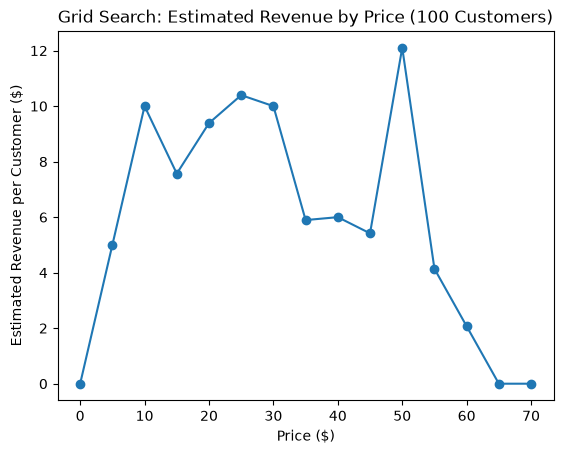

In [10]:
plt.plot(list(prices), results, marker="o")
plt.xlabel("Price ($)")
plt.ylabel("Estimated Revenue per Customer ($)")
plt.title("Grid Search: Estimated Revenue by Price (100 Customers)")
plt.show()

# Test 2: 300 Customers

In [11]:
#Trying a larger sample size:

prices = range(0, 71, 5)
results = []
grid_customers = 0
grid_revenue = 0

rng = np.random.default_rng(100)

for price in prices:
    purchases = sales(price, mean_customers=300, rng=rng) #300 Customers
    avg_revenue = purchases.mean() * price
    results.append(avg_revenue)

    grid_customers += len(purchases)
    grid_revenue += purchases.sum() * price

In [12]:
best_revenue = max(results)
best_index = results.index(best_revenue)
best_price = list(prices)[best_index]

print("Best price:", best_price)
print("Average revenue:", best_revenue)

Best price: 25
Average revenue: 10.606060606060606


In [13]:
#Gradient Ascent:
history2 = gradient_ascent(
    start_price=best_price,
    iterations=30,
    mean_customers=100,
    seed=100
)

history2.tail()

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,revenue,learning_rate,next_price
25,26,28.301809,-1.367381,1.015747,-3.038286,0.303523,193,2617.068264,0.392232,27.765478
26,27,27.765478,1.054524,0.938794,-0.489793,2.598841,213,2422.596610,0.384900,28.171365
27,28,28.171365,1.318814,1.033173,-0.380755,3.018384,179,2011.166903,0.377964,28.669830
28,29,28.669830,-1.502657,1.014353,-3.171268,0.165955,186,1749.859615,0.371391,28.111757
29,30,28.111757,0.099881,0.976583,-1.506598,1.706360,198,2134.493535,0.365148,28.148229


In [14]:
#Counting Customers:

gradient_customers = history2["customers"].sum()
total_customers = grid_customers + gradient_customers

print("Gradient ascent customers:", gradient_customers)
print("Total experimental customers:", total_customers)

Gradient ascent customers: 5987
Total experimental customers: 10459


In [15]:
#Calculating Revenue
gradient_revenue = history2["revenue"].sum()
total_revenue = grid_revenue + gradient_revenue

print("Total experimental revenue:", total_revenue)

Total experimental revenue: 95222.99742678776


In [16]:
#Evaluating Results Against Given Optimal Revenue

percent_captured = total_revenue / (total_customers * 11.925) * 100

print("Total customers:", total_customers)
print("Total revenue:", total_revenue)
print("Percentage of optimal revenue:", percent_captured)

Total customers: 10459
Total revenue: 95222.99742678776
Percentage of optimal revenue: 76.34723221074104


Better, try gradient repetitions = 15 to reduce customers used.

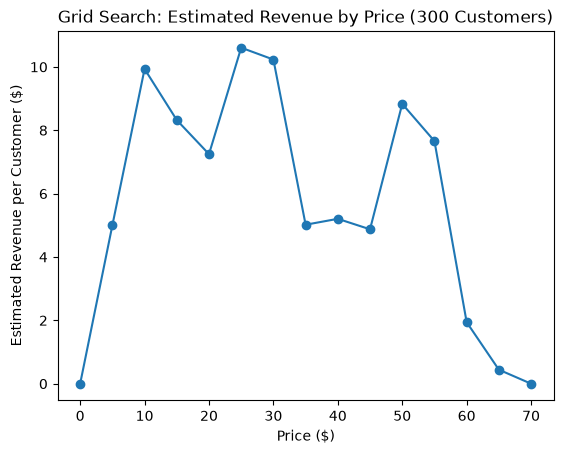

In [17]:
plt.plot(list(prices), results, marker="o")
plt.xlabel("Price ($)")
plt.ylabel("Estimated Revenue per Customer ($)")
plt.title("Grid Search: Estimated Revenue by Price (300 Customers)")
plt.show()

# Reduced Gradient:

In [18]:
#Gradient Ascent:
history = gradient_ascent(
    start_price=best_price,
    iterations=15,
    mean_customers=100,
    seed=100
)

history.tail()

,iteration,price,gradient,gradient_se,ci_low,ci_high,customers,revenue,learning_rate,next_price
10,11,27.124621,0.255360,0.952988,-1.312306,1.823025,200,2308.592748,0.603023,27.278608
11,12,27.278608,-0.142872,0.931379,-1.674991,1.389247,199,1937.781178,0.577350,27.196121
12,13,27.196121,0.399010,0.963693,-1.186266,1.984285,198,2294.474181,0.554700,27.417452
13,14,27.417452,-0.644932,0.976891,-2.251917,0.962053,197,2493.988119,0.534522,27.072721
14,15,27.072721,1.038720,0.952048,-0.527398,2.604839,198,2231.963134,0.516398,27.609114


In [19]:
#Counting Customers:

gradient_customers = history["customers"].sum()
total_customers = grid_customers + gradient_customers

print("Gradient ascent customers:", gradient_customers)
print("Total experimental customers:", total_customers)

Gradient ascent customers: 3068
Total experimental customers: 7540


In [20]:
#Calculating Revenue
gradient_revenue = history["revenue"].sum()
total_revenue = grid_revenue + gradient_revenue

print("Total experimental revenue:", total_revenue)

Total experimental revenue: 60634.77304528472


In [21]:
#Evaluating Results Against Given Optimal Revenue

percent_captured = total_revenue / (total_customers * 11.925) * 100

print("Total customers:", total_customers)
print("Total revenue:", total_revenue)
print("Percentage of optimal revenue:", percent_captured)

Total customers: 7540
Total revenue: 60634.77304528472
Percentage of optimal revenue: 67.43603428288509


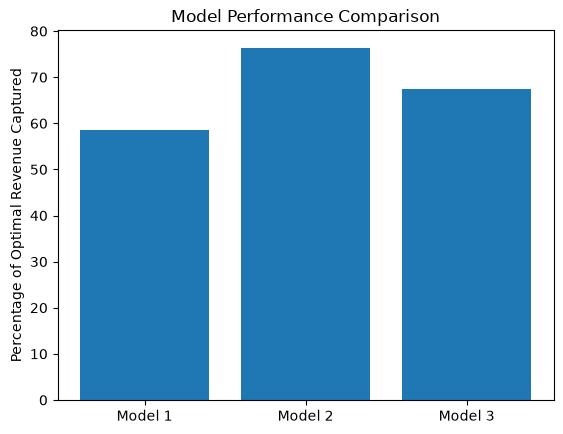

In [22]:
models = ["Model 1", "Model 2", "Model 3"]
percentages = [58.53, 76.35, 67.44]

plt.bar(models, percentages)
plt.ylabel("Percentage of Optimal Revenue Captured")
plt.title("Model Performance Comparison")
plt.show()

It appears model 2 is the best

# Experimenting with Different Seeds:

In [23]:
# Model 2 with seed 200:
rng = np.random.default_rng(200)

prices = range(0, 71, 5)
results = []
grid_customers = 0
grid_revenue = 0

for price in prices:
    purchases = sales(price, mean_customers=300, rng=rng)
    avg_revenue = purchases.mean() * price
    results.append(avg_revenue)

    grid_customers += len(purchases)
    grid_revenue += purchases.sum() * price

best_revenue = max(results)
best_index = results.index(best_revenue)
best_price = list(prices)[best_index]

history = gradient_ascent(
    start_price=best_price,
    iterations=30,
    mean_customers=100,
    seed=200
)

# Final price
final_price = history["next_price"].iloc[-1]

# Total customers and revenue
gradient_customers = history["customers"].sum()
gradient_revenue = history["revenue"].sum()

total_customers = grid_customers + gradient_customers
total_revenue = grid_revenue + gradient_revenue

# Compare with optimal revenue
percent_captured = total_revenue / (total_customers * 11.925) * 100

print("Grid search best price:", best_price)
print("Final estimated price:", final_price)
print("Total customers:", total_customers)
print("Total revenue:", total_revenue)
print("Percentage of optimal revenue captured:", percent_captured)

Grid search best price: 30
Final estimated price: 27.728873535980853
Total customers: 10486
Total revenue: 95587.47625008538
Percentage of optimal revenue captured: 76.44212548953992


In [24]:
# Model 2 with seed 300:
rng = np.random.default_rng(300)

prices = range(0, 71, 5)
results = []
grid_customers = 0
grid_revenue = 0

for price in prices:
    purchases = sales(price, mean_customers=300, rng=rng)
    avg_revenue = purchases.mean() * price
    results.append(avg_revenue)

    grid_customers += len(purchases)
    grid_revenue += purchases.sum() * price

best_revenue = max(results)
best_index = results.index(best_revenue)
best_price = list(prices)[best_index]

history = gradient_ascent(
    start_price=best_price,
    iterations=30,
    mean_customers=100,
    seed=300
)

# Final price
final_price = history["next_price"].iloc[-1]

# Total customers and revenue
gradient_customers = history["customers"].sum()
gradient_revenue = history["revenue"].sum()

total_customers = grid_customers + gradient_customers
total_revenue = grid_revenue + gradient_revenue

# Compare with optimal revenue
percent_captured = total_revenue / (total_customers * 11.925) * 100

print("Grid search best price:", best_price)
print("Final estimated price:", final_price)
print("Total customers:", total_customers)
print("Total revenue:", total_revenue)
print("Percentage of optimal revenue captured:", percent_captured)

Grid search best price: 25
Final estimated price: 26.80127580858408
Total customers: 10375
Total revenue: 96584.36228368327
Percentage of optimal revenue captured: 78.0657117293795


Results are consistent with the original model 2